### Laboratorium 4, cześć 2: Transformacja Hougha

#### _Fabuła_
_Budujemy aplikację do szkolenia snookerzystów. Jej celem będzie, między innymi, analiza pozycji i sugerowanie zagrań. Naturalnie, podstawą działania aplikacji musi być funkcjonalność detekcji bil i określenia ich pozycji w układzie współrzędnych stołu. W dalszych etapach określane będą geometryczne relacje między bilami i łuzami - ich implementacją zajmie się jednak inny zespół._

#### Zadanie
Twoim celem będzie wykonanie detekcji **bil** oraz **band** za pomocą transformacji Hougha.
Przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający dwie kolekcje: jedną reprezentującą okręgi (bile), drugą - linie/odcinki (bandy) lub punkty (narożniki stołu).
Format tych kolekcji jest dowolny, szczegóły implementacji potoku podobnie.
W ogólności, potok powinien składać się z:
* etapu przetwarzania wstępnego - skorzystaj ze swojego ulubionego detektora krawędzi,
* wykonania transformacji Hougha dla linii ([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) do wykrycia band,
* wykonania transformacji Hougha dla okręgów ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) do wykrycia bil,
* przetwarzania końcowego wyników transformacji (np. usunięcie nadmiarowych/fałszywych detekcji).

Zaimplementuj również funkcję prezentującą wyniki w formie wizualnej, tj. rysującej wykryte obiekty na kopii obrazu wejściowego.

Dane są cztery obrazy.
Staraj się prowadzić eksperymenty na jednym czy dwóch, a następnie zaprezentować wyniki na pozostałych.

#### Oczekiwane rezultaty
1. Zacznij od znalezienia odpowiednich parametrów detektora krawędzi - jeśli na tym etapie wyniki będą słabe, to dalej będzie tylko gorzej (_garbage-in, garbage-out_). Nie skupiaj się na badaniu ich wpływu na wyniki końcowe, a jedynie przedstaw efekt przetwarzania wstępnego, tj. jak wygląda obraz, na którym wykonywana będzie TH. Ta część zadania będzie oceniana binarnie: dobrze/źle.
2. Kalibracja parametrów transformacji Hougha: zadanie **NIE** polega na zrobieniu grid searchu po parametrach TH (wykonanie go nie jest _zabronione_, po prostu nie umieszczaj go w notatniku). Interesujące jest jedynie zrozumienie działania poszczególnych parametrów i ich wpływu na wyniki - pozostaw w notatniku jedynie kilka przykładowych wyników, takich które ilustrują dokonane przez Ciebie wybory parametrów (_ustawiam parametr $x$ na wartość $x_0$, bo przy wartości $x_1$ działo się tak a tak_).
3. Demonstracja wyników na pozostałych obrazach: przedstaw obraz wejściowy, wykryte krawędzie, wykryte obiekty. Efektem powinny być 4 (lub 6) linii reprezentujących bandy, oraz zbiór okręgów odpowiadających bilom (w idealnym przypadku 1:1, ale nie musisz poświęcać długich godzin na wyeliminowaniu _wszystkich_ błędów, ważniejsze jest by umieć wyjaśnić, skąd się wzięły).


#### Literatura
1. Dokumentacja funkcji([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) i ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) - działanie parametrów jest bardzo dobrze opisane.
2. Jeśli chcesz poznać TH "od środka" - [tutaj](https://medium.com/@alb.formaggio/implementing-the-hough-transform-from-scratch-09a56ba7316b) ktoś zaimplementował ją od zera. Czytając, uważaj tylko, by nie powtórzyć po Alberto jego błędu (krawędzie!)
3. Źródło danych do zadania: kompilacja [TOP 40 SHOTS of 2025 British Open](https://www.youtube.com/watch?v=5oZ3fIF9qog) autorstwa GTKomissaRa.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

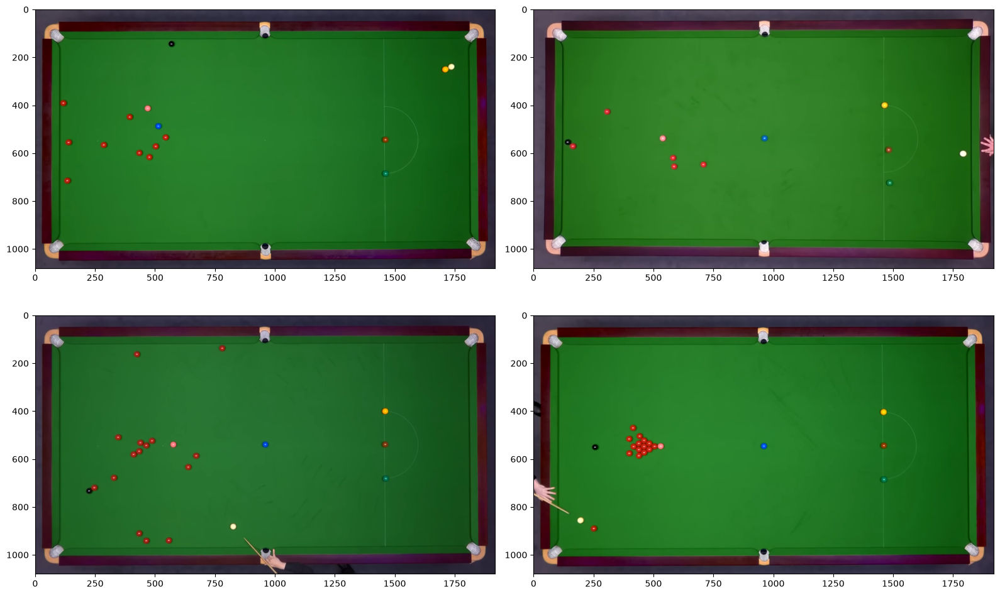

In [2]:
# zbiór danych
mcgill = cv2.imread('Lab4_dane/mcgill.png')
trump = cv2.imread('Lab4_dane/trump.png')
zhao = cv2.imread('Lab4_dane/zhao.png')
mcgill2 = cv2.imread('Lab4_dane/mcgill2.png')
assert all(x is not None for x in (mcgill, trump, zhao, mcgill2)), 'Nie wczytano obrazów - sprawdź ścieżkę'
# tu wyświetlone są wszystkie naraz w pomniejszeniu
# w eksperymentach staraj się wyświetlać je w dużym rozmiarze (albo używaj RoI)
_, axes = plt.subplots(2, 2, figsize=(16,10))
axes.ravel()[0].imshow(mcgill[..., ::-1])
axes.ravel()[1].imshow(trump[..., ::-1])
axes.ravel()[2].imshow(zhao[..., ::-1])
axes.ravel()[3].imshow(mcgill2[..., ::-1])
plt.tight_layout()

In [3]:
# funkcje pomocnicze do wyświetlania
def show(img, title=None, figsize=(16, 9), ax=None):
    """Wyświetla obraz BGR (3 kanały) lub jednokanałowy."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if img.ndim == 3:
        ax.imshow(img[..., ::-1])
    else:
        ax.imshow(img, cmap='gray')
    ax.set_title(title); ax.axis('off')
    return ax

def show_grid(imgs, titles, ncols=2, figsize=(18, 10)):
    nrows = int(np.ceil(len(imgs) / ncols))
    _, axes = plt.subplots(nrows, ncols, figsize=figsize)
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, img, t in zip(np.ravel(axes), imgs, titles):
        show(img, t, ax=ax)
    plt.tight_layout(); plt.show()

Eksperymenty i kalibrację prowadzę wyłącznie na **`mcgill`** i **`mcgill2`** (w `mcgill2` jest ciasny trójkąt czerwonych bil, najtrudniejszy przypadek dla okręgów).
**`trump`** i **`zhao`** pokazuję dopiero w demonstracji wyników (sekcja 6).

## 1. Obszar stołu

Wszystkie kadry są z tej samej kamery nad stołem, więc przycinam je jednym stałym prostokątem `TABLE`, ustawionym ręcznie na `mcgill` i `mcgill2`: drewniana rama stołu kończy się tam na x ≈ 30 i 1884 oraz y ≈ 50 i 1046, a prostokąt ma ok. 10 px zapasu.
Odpada podłoga i większa część postaci zawodnika. Wszystkie współrzędne w dalszej części są w układzie przyciętego obrazu.

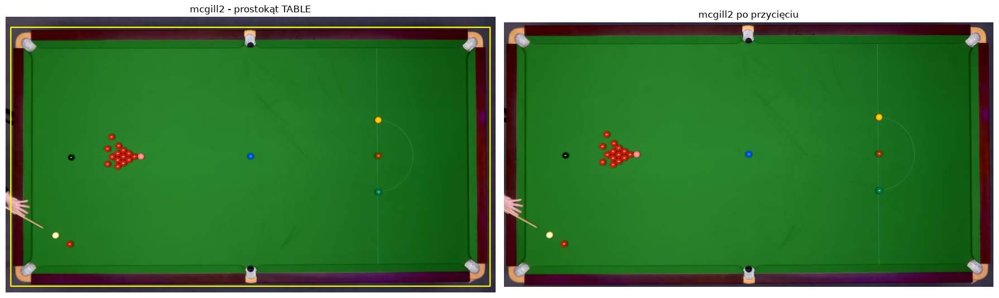

In [4]:
TABLE = (slice(40, 1056), slice(20, 1900))   # wiersze, kolumny - ten sam prostokąt dla każdego obrazu

def crop_table(img):
    return img[TABLE].copy()

vis = mcgill2.copy()
cv2.rectangle(vis, (TABLE[1].start, TABLE[0].start), (TABLE[1].stop - 1, TABLE[0].stop - 1), (0, 255, 255), 4)
show_grid([vis, crop_table(mcgill2)], ['mcgill2 - prostokąt TABLE', 'mcgill2 po przycięciu'], ncols=2, figsize=(18, 5.5))

mcgill_c, mcgill2_c = crop_table(mcgill), crop_table(mcgill2)

# RoI do podglądu z bliska (wiersze, kolumny w układzie przyciętego obrazu)
ROI_CORNER = (slice(0, 260), slice(0, 380))      # lewy górny róg stołu
ROI_PACK = (slice(380, 580), slice(310, 560))    # trójkąt czerwonych w mcgill2

## 2. Przetwarzanie wstępne

Kanał **L\*** (Lab) → rozmycie Gaussa 5×5 → detektor Canny'ego z progami 20 / 40.
* L\* zamiast skali szarości, bo czerwona bila ma w skali szarości prawie tę samą jasność co sukno i jej brzeg wychodzi niepełny.
* Gauss 5×5, bo obraz ma mało szumu. Mocniejsze rozmycie zlewa szczeliny między stykającymi się bilami i osłabia bandę.
* Progi są niskie, bo banda (ciemna linia na zielonym tle, opisana w sekcji 3) jest ciemniejsza od sukna tylko o ok. 15 poziomów L\*. Przy progach 30 / 60 dolna banda w `mcgill2` prawie znika z mapy krawędzi.
  Dolny próg to połowa górnego, tak jak w Cannym wewnątrz `HoughCircles` (`param1` = 40), więc linie i okręgi dostają tę samą mapę krawędzi.

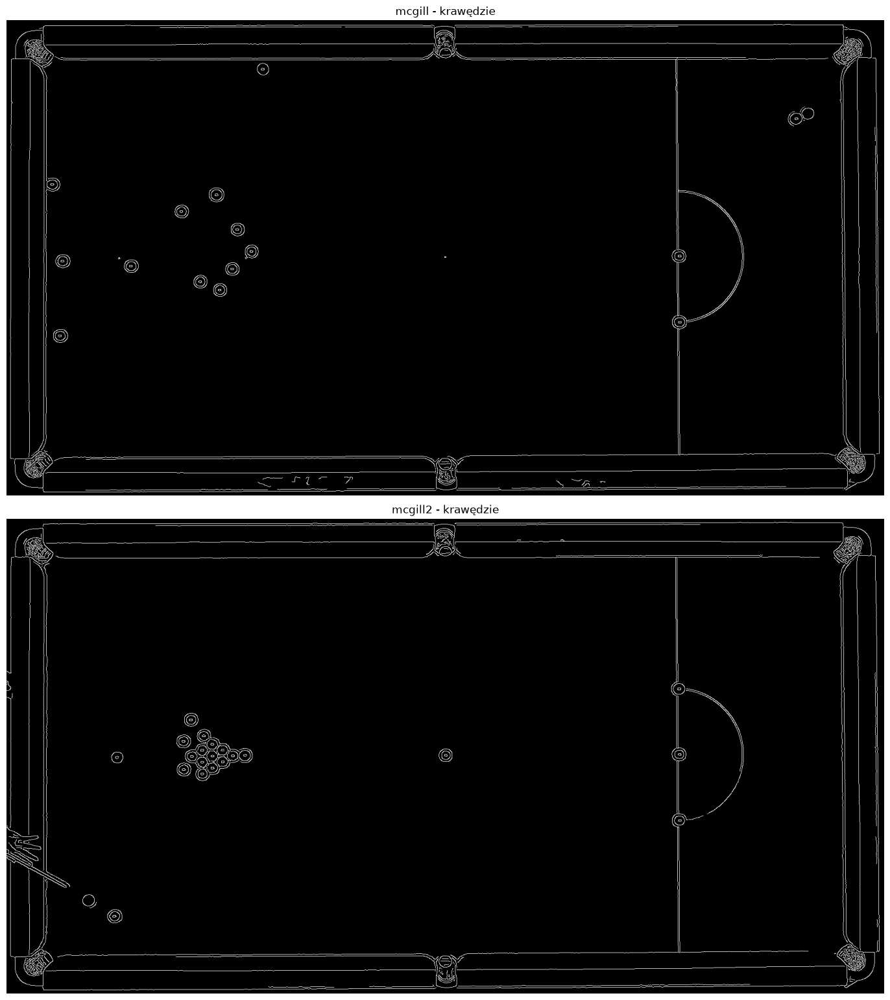

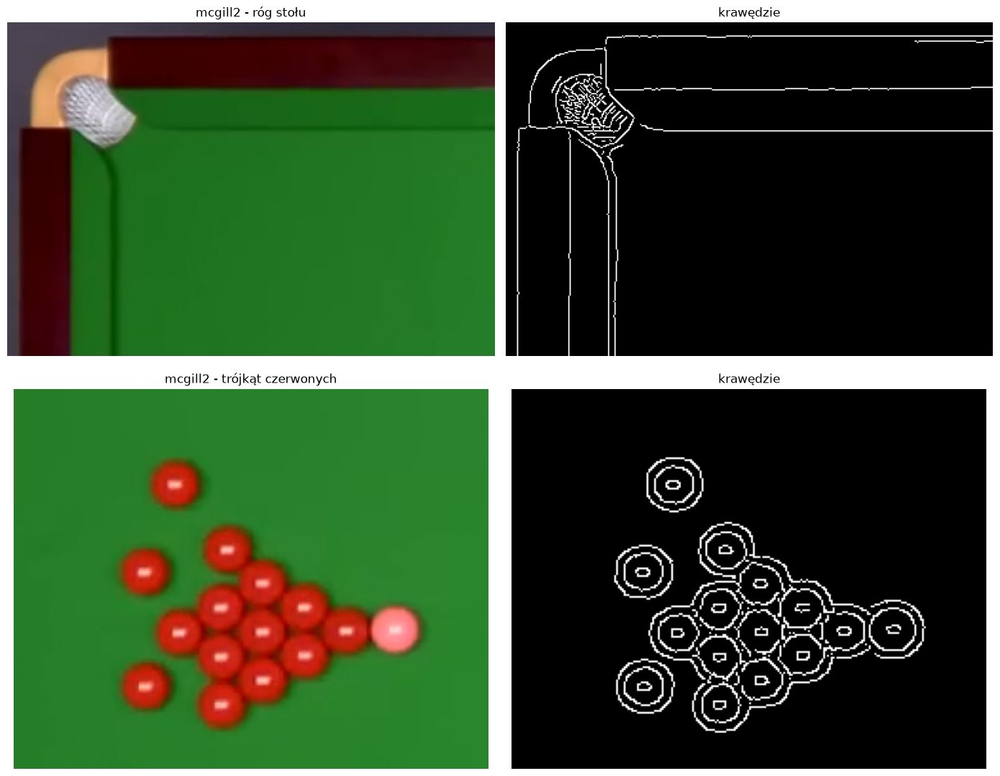

In [5]:
BLUR_K = (5, 5)
CANNY_LO, CANNY_HI = 20, 40

def preprocess(img_bgr):
    """L* (Lab) -> rozmycie Gaussa -> Canny. Zwraca (obraz wygładzony, mapa krawędzi)."""
    L = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)[..., 0]
    smooth = cv2.GaussianBlur(L, BLUR_K, 0)
    edges = cv2.Canny(smooth, CANNY_LO, CANNY_HI)
    return smooth, edges

smooth_m, edges_m = preprocess(mcgill_c)
smooth_m2, edges_m2 = preprocess(mcgill2_c)

show_grid([edges_m, edges_m2], ['mcgill - krawędzie', 'mcgill2 - krawędzie'], ncols=1, figsize=(14, 15.5))
show_grid([mcgill2_c[ROI_CORNER], edges_m2[ROI_CORNER], mcgill2_c[ROI_PACK], edges_m2[ROI_PACK]],
          ['mcgill2 - róg stołu', 'krawędzie', 'mcgill2 - trójkąt czerwonych', 'krawędzie'],
          ncols=2, figsize=(14, 11))

Na suknie są tylko krawędzie bil, linii baulk i półkola D (w `mcgill2` także kija i dłoni zawodnika).
Każda bila daje dwa zamknięte pierścienie: brzeg (r ≈ 13-15 px) i wewnętrzny pierścień cieniowania (r ≈ 9-10 px). W trójkącie widać szczeliny między bilami.
Przy każdej bandzie są trzy równoległe krawędzie: zewnętrzny brzeg ramy, granica drewno/sukno i banda. Banda to ciemna linia, więc daje dwie bliskie krawędzie, po jednej z każdej strony linii.

## 3. Transformacja Hougha dla linii (bandy)

Banda to zielony wał wzdłuż pola gry. Od strony pola gry kończy się **ciemną linią między dwoma zielonymi pasami** (wierzchem bandy i suknem) i tę linię wykrywam jako bandę, bo od niej odbijają się bile.
Na lewej i prawej bandzie linia ma 6-7 px, na górnej i dolnej 4-5 px. Granica drewno/sukno to zewnętrzny brzeg wierzchu bandy.

`cv2.HoughLines(image, rho, theta, threshold)`:
* `rho`, `theta` - rozdzielczość akumulatora (odległość od początku układu w px i kąt normalnej w radianach),
* `threshold` - minimalna liczba głosów (pikseli krawędzi), żeby prosta została zwrócona.

Używam wariantu `HoughLinesWithAccumulator`, który poza $(\rho, \theta)$ zwraca liczbę głosów, potrzebną w przetwarzaniu końcowym.

In [6]:
def hough_lines(edges, rho=1, theta=np.pi/180, threshold=300):
    """Zwraca tablicę (N, 3): rho, theta, liczba głosów."""
    L = cv2.HoughLinesWithAccumulator(edges, rho, theta, threshold)
    return np.zeros((0, 3)) if L is None else L.reshape(-1, 3)

def draw_lines(img, lines, color=(0, 255, 255), thickness=2):
    out = img.copy()
    for rho, theta in np.asarray(lines)[:, :2]:
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        p1 = (int(x0 - 4000 * b), int(y0 + 4000 * a))
        p2 = (int(x0 + 4000 * b), int(y0 - 4000 * a))
        cv2.line(out, p1, p2, color, thickness, cv2.LINE_AA)
    return out

def line_pos(rho, theta, shape):
    """Klasyfikuje prostą jako poziomą 'H' / pionową 'V' i zwraca jej położenie:
    y w środkowej kolumnie (dla H) albo x w środkowym wierszu (dla V)."""
    H, W = shape[:2]
    if abs(np.sin(theta)) > abs(np.cos(theta)):
        return 'H', (rho - W / 2 * np.cos(theta)) / np.sin(theta)
    return 'V', (rho - H / 2 * np.sin(theta)) / np.cos(theta)

def describe(lines, shape):
    """Krótki opis: ile prostych i gdzie leżą (posortowane położenia)."""
    pos = [line_pos(r, t, shape) for r, t, _ in lines]
    hs = sorted(round(float(p)) for k, p in pos if k == 'H')
    vs = sorted(round(float(p)) for k, p in pos if k == 'V')
    return f'{len(lines)} prostych | poziome y={hs} | pionowe x={vs}'

### 3.1. Pierwsze podejście

Parametry startowe: `rho=1`, `theta=1°`, `threshold=200`.

35 prostych | poziome y=[9, 14, 50, 52, 80, 84, 929, 930, 933, 934, 938, 945, 948, 965, 967, 972, 997, 1002, 1004, 1008, 1008] | pionowe x=[9, 48, 50, 80, 85, 1435, 1437, 1438, 1788, 1792, 1793, 1828, 1862, 1865]


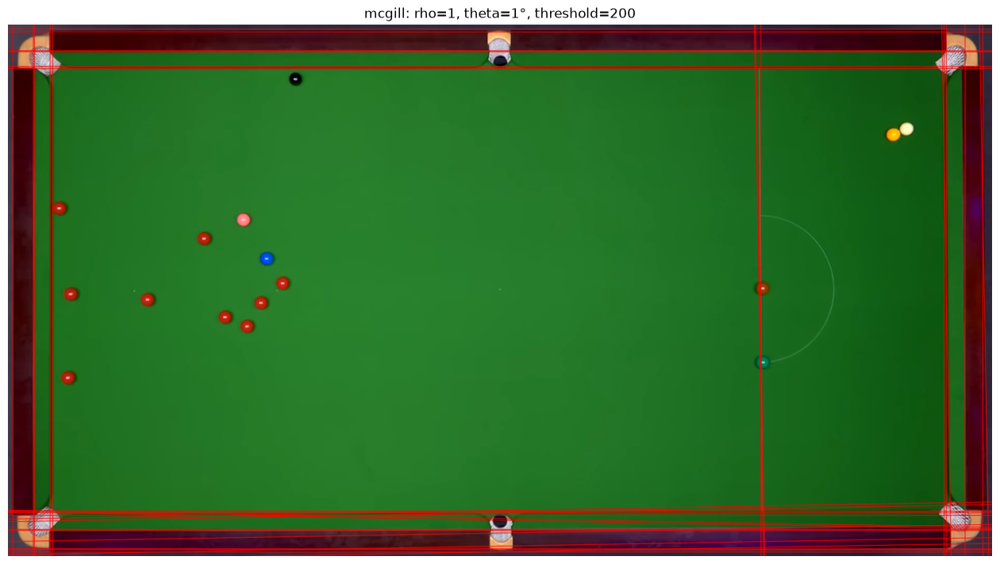

In [7]:
L0 = hough_lines(edges_m, 1, np.pi/180, 200)
print(describe(L0, mcgill_c.shape))
show(draw_lines(mcgill_c, L0, (0, 0, 255), 1), 'mcgill: rho=1, theta=1°, threshold=200');

Wynik jest zły: przy każdej bandzie jest po kilka prostych (trzy równoległe krawędzie, a każda w 2-3 wariantach różniących się o 1 px / 1°), do tego linia baulk (x ≈ 1437).
Sprawdzam, czy pomoże wyższy próg.

### 3.2. Wpływ `threshold` i `theta`

theta=1.00°, threshold=200       35 prostych | poziome y=[9, 14, 50, 52, 80, 84, 929, 930, 933, 934, 938, 945, 948, 965, 967, 972, 997, 1002, 1004, 1008, 1008] | pionowe x=[9, 48, 50, 80, 85, 1435, 1437, 1438, 1788, 1792, 1793, 1828, 1862, 1865]
theta=1.00°, threshold=600       4 prostych | poziome y=[9, 50, 80, 84] | pionowe x=[]
theta=0.25°, threshold=600       10 prostych | poziome y=[9, 50, 80, 81, 84, 931, 933, 966, 1001, 1005] | pionowe x=[]
theta=0.25°, threshold=300       58 prostych


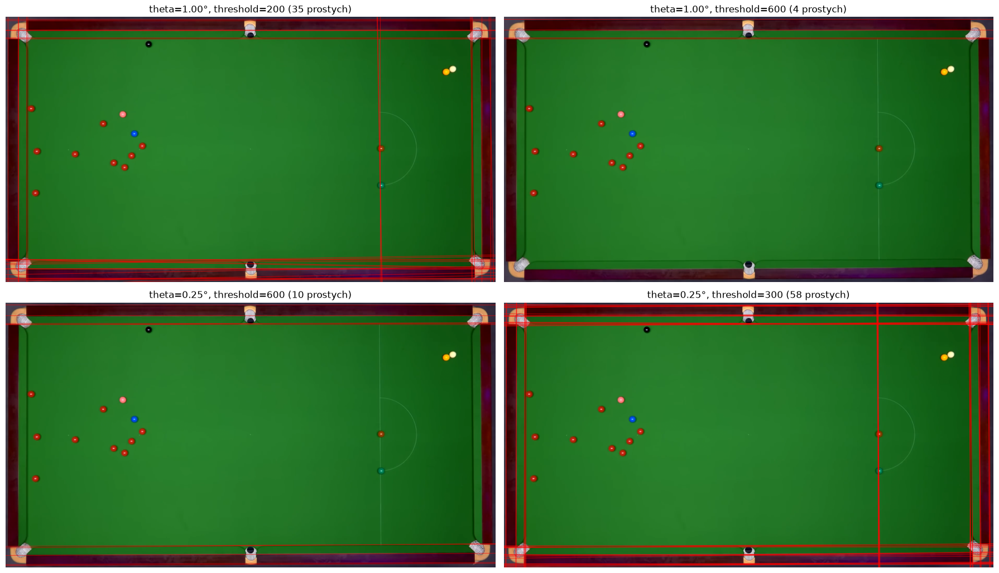

In [8]:
configs = [(np.pi/180, 200), (np.pi/180, 600), (np.pi/720, 600), (np.pi/720, 300)]
imgs, titles = [], []
for theta, thr in configs:
    L = hough_lines(edges_m, 1, theta, thr)
    name = f'theta={np.degrees(theta):.2f}°, threshold={thr}'
    print(f'{name:32s}', describe(L, mcgill_c.shape) if len(L) < 40 else f'{len(L)} prostych')
    imgs.append(draw_lines(mcgill_c, L, (0, 0, 255), 1))
    titles.append(f'{name} ({len(L)} prostych)')
show_grid(imgs, titles, ncols=2, figsize=(18, 10.5))

* **`threshold`**: przy 1° i 600 głosach zostają 4 proste, wszystkie przy **górnej** bandzie. Pozostałe bandy znikają:
  * lewa i prawa, bo są krótkie (ok. 750 px między łuzami narożnymi) i zbierają tylko 470-610 głosów,
  * dolna i prawa także przez perspektywę: są nachylone o 0,25-0,5°, więc przy rozdzielczości kąta 1° ich piksele głosują na dwie sąsiednie komórki akumulatora i żadna nie zbiera kompletu.

  Wyższy próg usuwa więc bandy wcześniej niż duplikaty.
* **`theta`**: przy 0,25° nachylone bandy dostają pełną liczbę głosów i przy progu 600 pojawia się dolna banda (y ≈ 931). Przybywa przy tym niemal identycznych prostych, które scalam w przetwarzaniu końcowym.
* **`threshold=300`** (przy `theta=0.25°`): najsłabsza banda na obu obrazach (prawa w `mcgill`) ma 470 głosów, więc wybieram próg ok. 1/3 niższy. Przy 400 wynik jest ten sam, przy 500 w `mcgill` znika lewa i prawa banda.
  Długie bandy są przerwane środkową łuzą, ale `HoughLines` zwraca proste nieskończone, więc obie połówki głosują na tę samą parę $(\rho, \theta)$. Dlatego wynikiem są 4 proste, a nie 6.
* **`rho=1`** - zostawiam: równoległe krawędzie przy bandzie są oddalone o 30-40 px, więc rozdzielczość 1 px ich nie skleja, a daje dokładne położenie.

### 3.3. Przetwarzanie końcowe linii

1. **Orientacja**: zostawiam proste prawie poziome lub pionowe (odchylenie < 5°).
2. **Położenie**: banda leży w pasie 15% szerokości/wysokości obrazu przy jego brzegu, co przypisuje prostą do strony stołu (góra / dół / lewo / prawo) i usuwa linię baulk. Bandy leżą najdalej 8,4% od brzegu, a linia baulk 23,6%, więc działa każda wartość z tego przedziału.
3. **Kryterium sukna**: dla każdej prostej mierzę ułamek pikseli sukna 8 px po obu jej stronach. Banda ma sukno po obu stronach (wierzch bandy i pole gry), granica drewno/sukno tylko po wewnętrznej, a brzeg ramy po żadnej. Zostawiam proste z suknem po obu stronach (≥ 0,5).
4. **Środek ciemnej linii**: zostają krawędzie ciemnej linii, każda w kilku wariantach kąta. Najsilniejsza bywa raz krawędzią wewnętrzną, raz zewnętrzną, więc bandą jest średnia ważona głosami prostych leżących do 10 px od najsilniejszej.

In [9]:
LINE_RHO, LINE_THETA, LINE_THR = 1, np.pi/720, 300
MAX_TILT_DEG = 5        # dopuszczalne odchylenie od poziomu/pionu
BORDER_FRAC = 0.15      # banda leży w pasie 15% szerokości/wysokości przy brzegu obrazu
SIDE_OFFSET = 8         # odległość próbkowania koloru po obu stronach prostej [px]
MIN_CLOTH = 0.5         # minimalny ułamek sukna po każdej stronie prostej
NOSE_TOL = 10           # proste do 10 px od najsilniejszej należą do tej samej ciemnej linii
SIDES = ('top', 'bottom', 'left', 'right')

def cloth_mask(img_bgr):
    """Maska zielonego sukna (HSV)."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, (45, 100, 60), (80, 255, 255))

def tilt_deg(theta):
    d = np.degrees(theta)
    return min(abs(d - 90), d, 180 - d)

def split_sides(lines, shape):
    """Kroki 1-2: proste prawie poziome/pionowe w pasie przy brzegu obrazu, przypisane do stron."""
    H, W = shape[:2]
    sides = {s: [] for s in SIDES}
    for r, t, v in lines:
        if tilt_deg(t) >= MAX_TILT_DEG:
            continue
        k, p = line_pos(r, t, shape)
        if k == 'H':
            if p < BORDER_FRAC * H: sides['top'].append((r, t, v))
            elif p > (1 - BORDER_FRAC) * H: sides['bottom'].append((r, t, v))
        else:
            if p < BORDER_FRAC * W: sides['left'].append((r, t, v))
            elif p > (1 - BORDER_FRAC) * W: sides['right'].append((r, t, v))
    return sides

def cloth_fracs(rho, theta, mask, off=SIDE_OFFSET):
    """Ułamek pikseli sukna `off` px od prostej: (w stronę środka obrazu, na zewnątrz)."""
    H, W = mask.shape
    a, b = np.cos(theta), np.sin(theta)
    s = np.linspace(-4000, 4000, 8000)
    x, y = a * rho - b * s, b * rho + a * s
    inside = (x >= off) & (x < W - off) & (y >= off) & (y < H - off)
    x, y = x[inside], y[inside]
    if len(x) == 0:
        return 0.0, 0.0
    sgn = np.sign((W / 2 - a * rho) * a + (H / 2 - b * rho) * b)  # normalna skierowana do środka
    def frac(d):
        xs = np.clip((x + sgn * d * a).astype(int), 0, W - 1)
        ys = np.clip((y + sgn * d * b).astype(int), 0, H - 1)
        return (mask[ys, xs] > 0).mean()
    return frac(off), frac(-off)

def group_lines(lines, shape, tol=NOSE_TOL):
    """Grupuje proste leżące do `tol` px od najsilniejszej w grupie; grupy od najsilniejszej."""
    groups = []
    for l in sorted(lines, key=lambda l: -l[2]):
        p = line_pos(l[0], l[1], shape)[1]
        for g in groups:
            if abs(line_pos(g[0][0], g[0][1], shape)[1] - p) < tol:
                g.append(l); break
        else:
            groups.append([l])
    return groups

def mean_line(group):
    """Średnia (rho, theta) ważona głosami. Prostą z theta bliskim pi zapisuję jako (-rho, theta - pi),
    żeby prawie pionowe proste o theta ~0 i ~pi dało się uśredniać."""
    rt = np.array([(-r, t - np.pi) if t > 3 * np.pi / 4 else (r, t) for r, t, _ in group])
    w = np.array([v for *_, v in group])
    return tuple(rt.T @ w / w.sum())

def select_cushions(img_bgr, lines, verbose=False):
    """Kroki 1-4. Zwraca słownik strona -> (rho, theta) bandy."""
    mask = cloth_mask(img_bgr)
    result = {}
    for side, cands in split_sides(lines, img_bgr.shape).items():
        good = [l for l in cands if min(cloth_fracs(l[0], l[1], mask)) >= MIN_CLOTH]
        if good:
            result[side] = mean_line(group_lines(good, img_bgr.shape)[0])
        if verbose:
            reps = sorted((line_pos(g[0][0], g[0][1], img_bgr.shape)[1], g[0]) for g in group_lines(cands, img_bgr.shape))
            desc = ', '.join(f'{p:.0f} px (głosy {l[2]:.0f}, sukno {cloth_fracs(l[0], l[1], mask)[0]:.2f}/{cloth_fracs(l[0], l[1], mask)[1]:.2f})'
                             for p, l in reps)
            chosen = f'{line_pos(*result[side], img_bgr.shape)[1]:.1f} px' if side in result else 'brak!'
            print(f'{side:6s}: {desc}  ->  banda {chosen}')
    return result

def intersect(l1, l2):
    (r1, t1), (r2, t2) = l1, l2
    A = np.array([[np.cos(t1), np.sin(t1)], [np.cos(t2), np.sin(t2)]])
    return np.linalg.solve(A, [r1, r2])

def table_corners(cushions):
    """Narożniki pola gry w kolejności: lewy-górny, prawy-górny, prawy-dolny, lewy-dolny."""
    c = cushions
    return np.array([intersect(c['top'], c['left']), intersect(c['top'], c['right']),
                     intersect(c['bottom'], c['right']), intersect(c['bottom'], c['left'])], np.float32)

== mcgill: TH 58 -> orientacja i położenie 52 -> sukno po obu stronach 21 -> 4 bandy
   krawędzie przy każdej bandzie (grupy co 10 px; sukno: w stronę środka / na zewnątrz):
top   : 9 px (głosy 631, sukno 0.00/0.00), 50 px (głosy 917, sukno 0.89/0.00), 84 px (głosy 868, sukno 0.92/0.88)  ->  banda 81.9 px
bottom: 931 px (głosy 833, sukno 0.93/0.89), 966 px (głosy 823, sukno 0.90/0.00), 1005 px (głosy 753, sukno 0.00/0.00)  ->  banda 933.4 px
left  : 9 px (głosy 497, sukno 0.00/0.00), 48 px (głosy 437, sukno 0.85/0.00), 85 px (głosy 483, sukno 0.85/0.82)  ->  banda 82.3 px
right : 1796 px (głosy 470, sukno 0.84/0.81), 1826 px (głosy 459, sukno 0.83/0.00), 1866 px (głosy 473, sukno 0.00/0.00)  ->  banda 1792.5 px

== mcgill2: TH 56 -> orientacja i położenie 51 -> sukno po obu stronach 19 -> 4 bandy
   krawędzie przy każdej bandzie (grupy co 10 px; sukno: w stronę środka / na zewnątrz):
top   : 10 px (głosy 733, sukno 0.00/0.00), 49 px (głosy 889, sukno 0.89/0.00), 83 px (głosy 655, sukno

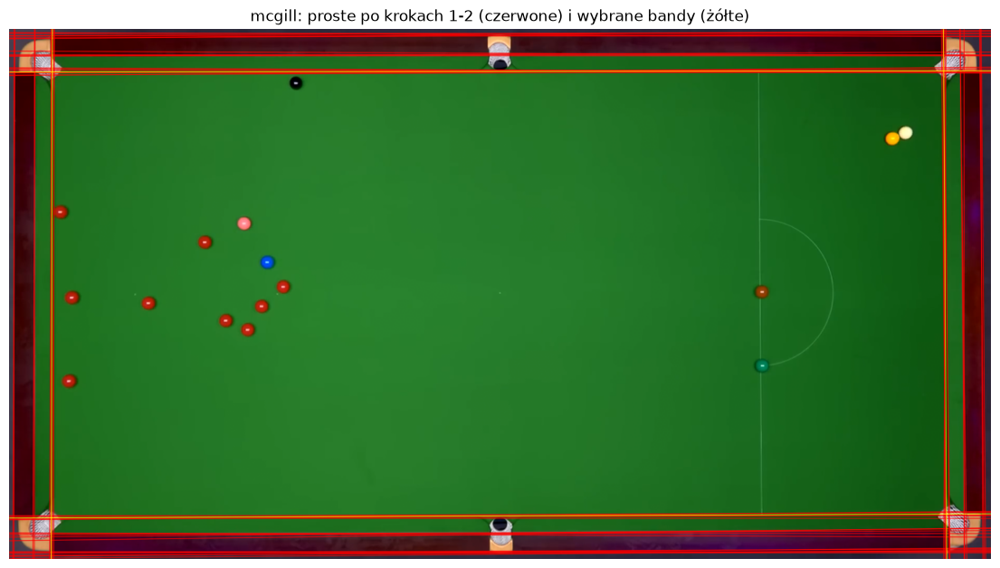

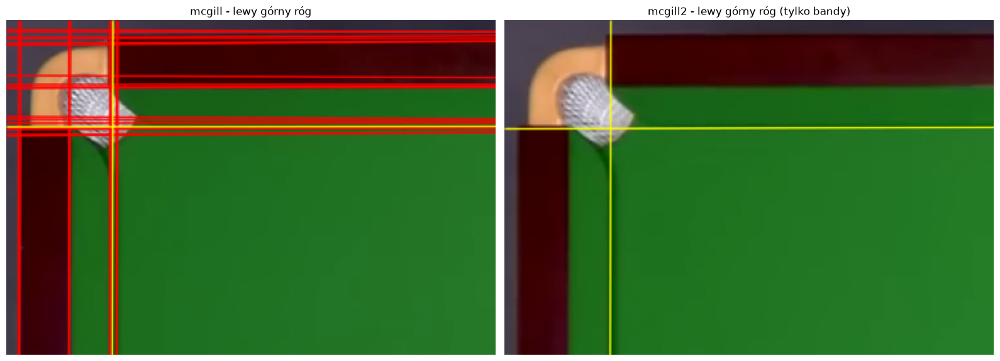

In [10]:
for name, img, edges in [('mcgill', mcgill_c, edges_m), ('mcgill2', mcgill2_c, edges_m2)]:
    raw = hough_lines(edges, LINE_RHO, LINE_THETA, LINE_THR)
    sides = split_sides(raw, img.shape)
    mask = cloth_mask(img)
    n_side = sum(len(v) for v in sides.values())
    n_cloth = sum(min(cloth_fracs(r, t, mask)) >= MIN_CLOTH for v in sides.values() for r, t, _ in v)
    print(f'== {name}: TH {len(raw)} -> orientacja i położenie {n_side} -> sukno po obu stronach {n_cloth} -> 4 bandy')
    print('   krawędzie przy każdej bandzie (grupy co 10 px; sukno: w stronę środka / na zewnątrz):')
    select_cushions(img, raw, verbose=True)
    print()

raw_m = hough_lines(edges_m, LINE_RHO, LINE_THETA, LINE_THR)
cushions_m = select_cushions(mcgill_c, raw_m)
cushions_m2 = select_cushions(mcgill2_c, hough_lines(edges_m2, LINE_RHO, LINE_THETA, LINE_THR))
cands_m = [l for v in split_sides(raw_m, mcgill_c.shape).values() for l in v]
vis = draw_lines(mcgill_c, cands_m, (0, 0, 255), 1)
vis = draw_lines(vis, [(*l, 0) for l in cushions_m.values()], (0, 255, 255), 1)
show(vis, 'mcgill: proste po krokach 1-2 (czerwone) i wybrane bandy (żółte)', figsize=(14, 8))
vis2 = draw_lines(mcgill2_c, [(*l, 0) for l in cushions_m2.values()], (0, 255, 255), 1)
show_grid([vis[ROI_CORNER], vis2[ROI_CORNER]], ['mcgill - lewy górny róg', 'mcgill2 - lewy górny róg (tylko bandy)'],
          ncols=2, figsize=(16, 5.8))

Na każdej stronie są trzy grupy prostych: brzeg ramy (sukno 0,00 / 0,00), granica drewno/sukno (ok. 0,85 / 0,00) i banda (ok. 0,85 / 0,85).
Kryterium sukna zostawia tylko bandę, a uśredniona prosta leży na środku ciemnej linii (zbliżenia wyżej).
Sama liczba głosów wybierałaby różne krawędzie: w `mcgill` u góry granicę drewno/sukno, na dole bandę, a po bokach brzeg ramy.

## 4. Transformacja Hougha dla okręgów (bile)

`cv2.HoughCircles(image, method, dp, minDist, param1, param2, minRadius, maxRadius)` z metodą `HOUGH_GRADIENT`:
* `image` - obraz w odcieniach szarości, **nie** mapa krawędzi: metoda sama liczy Canny'ego, a kierunek gradientu bierze z operatora Sobela, więc binarne krawędzie psują kierunki. Podaję wygładzony kanał L\* z przetwarzania wstępnego,
* `dp` - odwrotność rozdzielczości akumulatora,
* `minDist` - minimalna odległość między środkami wykrytych okręgów,
* `param1` - górny próg Canny'ego (dolny = połowa),
* `param2` - próg akumulatora środków (im mniejszy, tym więcej okręgów, także fałszywych),
* `minRadius`, `maxRadius` - zakres promieni.

Wyniki oceniam względem ręcznie sprawdzonych środków bil (`GT_BALLS`, 16 w `mcgill` i 22 w `mcgill2`) i liczę tylko okręgi na polu gry (filtr z 4.5), bo łuzy odpadają tam niezależnie od parametrów TH.

### 4.1. Pierwsze podejście

Bez ograniczenia promienia, `param2=30`.

liczba okręgów: 2809 | mediana promienia: 258 px


r bez ograniczeń, param2=30 | mcgill:  5 trafionych, 2775 fałszywych, 11 pominiętych (z TH 2809) | mcgill2: 14 trafionych, 2741 fałszywych,  8 pominiętych (z TH 2797)


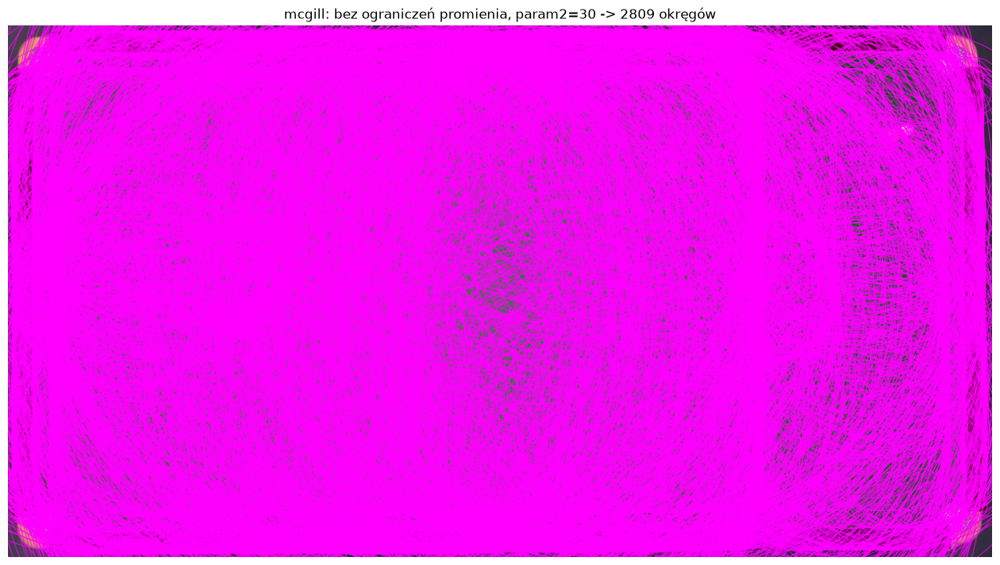

In [11]:
def hough_circles(smooth, dp=1, min_dist=15, param1=CANNY_HI, param2=15, min_r=7, max_r=18):
    C = cv2.HoughCircles(smooth, cv2.HOUGH_GRADIENT, dp, min_dist,
                         param1=param1, param2=param2, minRadius=min_r, maxRadius=max_r)
    return np.zeros((0, 3)) if C is None else C.reshape(-1, 3)

def draw_circles(img, circles, color=(255, 0, 255), thickness=2):
    out = img.copy()
    for x, y, r in circles:
        cv2.circle(out, (int(round(x)), int(round(y))), int(round(r)), color, thickness, cv2.LINE_AA)
        cv2.circle(out, (int(round(x)), int(round(y))), 2, color, -1)
    return out

CUSHION_MARGIN = 6      # środek bili co najmniej 6 px w głąb pola gry (uzasadnienie w 4.5)

def cushion_dists(x, y, cushions, shape):
    """Odległość punktu od każdej bandy, dodatnia po stronie pola gry (środka obrazu)."""
    H, W = shape[:2]
    return np.array([np.sign(W / 2 * np.cos(t) + H / 2 * np.sin(t) - rho) * (x * np.cos(t) + y * np.sin(t) - rho)
                     for rho, t in cushions.values()])

def filter_circles(circles, cushions, shape, margin=CUSHION_MARGIN):
    """Zostawia okręgi, których środek leży co najmniej `margin` px w głąb pola gry."""
    keep = [(x, y, r) for x, y, r in circles if cushion_dists(x, y, cushions, shape).min() >= margin]
    return np.array(keep).reshape(-1, 3)

# ręcznie sprawdzone środki bil w układzie przyciętego obrazu
GT_BALLS = {
    'mcgill': [(100, 350), (116, 678), (124, 514), (268, 526), (374, 408), (414, 558), (450, 372), (456, 576),
               (482, 532), (498, 446), (524, 494), (550, 104), (1442, 504), (1442, 646), (1690, 208), (1716, 200)],
    'mcgill2': [(176, 816), (232, 850), (236, 510), (380, 536), (382, 476), (396, 430), (396, 508), (418, 522),
                (420, 546), (420, 496), (422, 464), (440, 534), (440, 482), (442, 508), (462, 498), (464, 520),
                (486, 506), (510, 506), (940, 506), (1438, 504), (1440, 364), (1440, 646)],
}
CALIB = {'mcgill': (mcgill_c, smooth_m, cushions_m), 'mcgill2': (mcgill2_c, smooth_m2, cushions_m2)}

def evaluate(name, **params):
    """(trafione, fałszywe, pominięte, wszystkie okręgi z TH). Trafienie = środek < 8 px od bili."""
    img, smooth, cushions = CALIB[name]
    C = hough_circles(smooth, **params)
    on_table = filter_circles(C, cushions, img.shape)
    gt = np.array(GT_BALLS[name], float)
    hit = set()
    for x, y, _ in on_table:
        d = np.hypot(gt[:, 0] - x, gt[:, 1] - y)
        if d.min() < 8:
            hit.add(int(d.argmin()))
    return len(hit), len(on_table) - len(hit), len(gt) - len(hit), len(C)

def report(label, **params):
    cols = []
    for name in CALIB:
        tp, fp, fn, n = evaluate(name, **params)
        cols.append(f'{name}: {tp:2d} trafionych, {fp:4d} fałszywych, {fn:2d} pominiętych (z TH {n:4d})')
    print(f'{label:22s} | ' + ' | '.join(cols))

C0 = hough_circles(smooth_m, param2=30, min_r=0, max_r=0)
print('liczba okręgów:', len(C0), '| mediana promienia: %.0f px' % np.median(C0[:, 2]))
report('r bez ograniczeń, param2=30', param2=30, min_r=0, max_r=0)
show(draw_circles(mcgill_c, C0, thickness=1), f'mcgill: bez ograniczeń promienia, param2=30 -> {len(C0)} okręgów');

Prawie 3000 okręgów o promieniach rzędu setek pikseli. Bez ograniczenia promienia każdy piksel krawędzi głosuje na środki wzdłuż kierunku gradientu przez cały obraz, więc głosy z band, linii baulk, półkola D i łuz przecinają się przypadkowo w wielu miejscach i przekraczają próg.

### 4.2. Zakres promieni

Okręgi dopasowane do bil mają promień 9,1-16,3 px (mediana 12,2 px). Najmniejsze dopasowują się do wewnętrznego pierścienia krawędzi bili, największe w trójkącie obejmują też krawędzie sąsiadów.
Wynik jest poprawny dla dolnej granicy od 4 do 9 px i górnej od 14 do 22 px. Ustawiam `minRadius=7`, `maxRadius=18`, czyli mniej więcej środki obu przedziałów.

In [12]:
for min_r, max_r in [(0, 0), (5, 30), (7, 24), (10, 18), (7, 18)]:
    report(f'r = [{min_r}, {max_r}]', min_r=min_r, max_r=max_r)

r = [0, 0]             | mcgill: 15 trafionych, 3948 fałszywych,  1 pominiętych (z TH 4736) | mcgill2: 19 trafionych, 3894 fałszywych,  3 pominiętych (z TH 4652)
r = [5, 30]            | mcgill: 16 trafionych,    1 fałszywych,  0 pominiętych (z TH   62) | mcgill2: 20 trafionych,    5 fałszywych,  2 pominiętych (z TH   67)
r = [7, 24]            | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   40) | mcgill2: 21 trafionych,    1 fałszywych,  1 pominiętych (z TH   43)
r = [10, 18]           | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   29) | mcgill2: 21 trafionych,    0 fałszywych,  1 pominiętych (z TH   35)
r = [7, 18]            | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   30) | mcgill2: 22 trafionych,    0 fałszywych,  0 pominiętych (z TH   39)


* Bez ograniczenia promienia: kilka tysięcy fałszywych okręgów na polu gry.
* Za szeroko (5-30 albo już 7-24 px): w trójkącie `mcgill2` część bil przegrywa z większymi okręgami obejmującymi kilka bil i pojawiają się fałszywe okręgi (1-5).
* Za wąsko (10-18 px): ginie środkowa bila trójkąta.
* 7-18 px: wszystkie bile, zero fałszywych.

### 4.3. `param2` (próg akumulatora) i `param1` (próg Canny'ego)

Pokazuję trójkąt w `mcgill2`, bo tam różnice są najlepiej widoczne.

param2=30              | mcgill: 15 trafionych,    0 fałszywych,  1 pominiętych (z TH   16) | mcgill2: 14 trafionych,    0 fałszywych,  8 pominiętych (z TH   15)


param2=20              | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   26) | mcgill2: 21 trafionych,    0 fałszywych,  1 pominiętych (z TH   32)
param2=15              | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   30) | mcgill2: 22 trafionych,    0 fałszywych,  0 pominiętych (z TH   39)
param2=10              | mcgill: 16 trafionych,    1 fałszywych,  0 pominiętych (z TH   53) | mcgill2: 22 trafionych,    4 fałszywych,  0 pominiętych (z TH   73)


param2=5               | mcgill: 16 trafionych,   56 fałszywych,  0 pominiętych (z TH  235) | mcgill2: 22 trafionych,   67 fałszywych,  0 pominiętych (z TH  255)
param1=100             | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   29) | mcgill2: 20 trafionych,    0 fałszywych,  2 pominiętych (z TH   29)
param1=20              | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   32) | mcgill2: 22 trafionych,    0 fałszywych,  0 pominiętych (z TH   39)


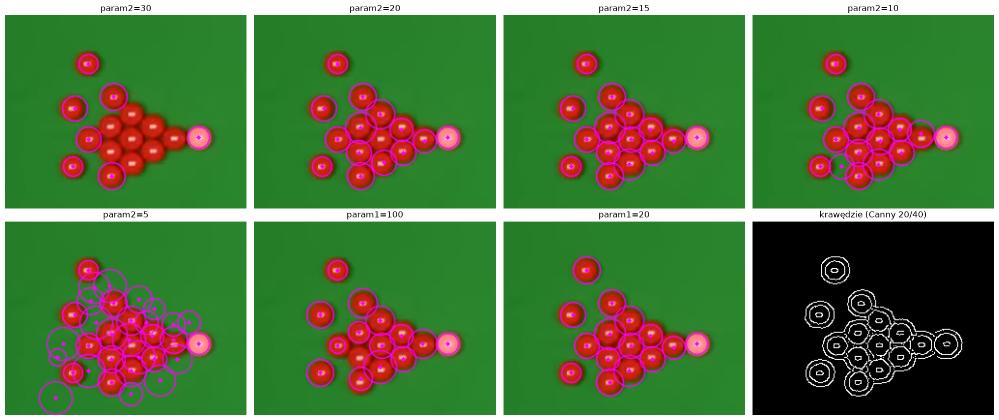

In [13]:
imgs, titles = [], []
for p2 in [30, 20, 15, 10, 5]:
    report(f'param2={p2}', param2=p2)
    imgs.append(draw_circles(mcgill2_c, hough_circles(smooth_m2, param2=p2), thickness=1)[ROI_PACK])
    titles.append(f'param2={p2}')
for p1 in [100, 20]:
    report(f'param1={p1}', param1=p1)
    imgs.append(draw_circles(mcgill2_c, hough_circles(smooth_m2, param1=p1), thickness=1)[ROI_PACK])
    titles.append(f'param1={p1}')
imgs.append(edges_m2[ROI_PACK]); titles.append('krawędzie (Canny 20/40)')
show_grid(imgs, titles, ncols=4, figsize=(20, 8.5))

* **`param2=30`** - za wysoki: w trójkącie brzegi stykających się bil częściowo zlewają się z sąsiednimi, więc ich okręgi krawędzi są niepełne i 8 bil z trójkąta (oraz 1 bila w `mcgill`) nie zbiera dość głosów. Przy 20 brakuje jeszcze środkowej bili trójkąta.
* **`param2=5`** - za niski: kilkadziesiąt fałszywych okręgów na łuku D i linii baulk, przy łuzach, na dłoni zawodnika i obok bil. Przy 10 są już 1 i 4 fałszywe.
* **`param2=15`** - wszystkie bile, zero fałszywych. Ten sam wynik daje cały zakres 12-19.
* **`param1`** - w zakresie 20-90 wynik się nie zmienia. Przy 100 wewnętrzny Canny gubi słabe krawędzie i znika bila z trójkąta oraz zielona bila, która ma najmniejszy kontrast z suknem. Zostawiam `param1=40`, czyli dokładnie mapę krawędzi z przetwarzania wstępnego.

### 4.4. `minDist` i `dp`

minDist=5              | mcgill: 16 trafionych,    7 fałszywych,  0 pominiętych (z TH   83) | mcgill2: 22 trafionych,   12 fałszywych,  0 pominiętych (z TH   92)
minDist=15             | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   30) | mcgill2: 22 trafionych,    0 fałszywych,  0 pominiętych (z TH   39)
minDist=25             | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   28) | mcgill2: 19 trafionych,    0 fałszywych,  3 pominiętych (z TH   30)
minDist=40             | mcgill: 15 trafionych,    0 fałszywych,  1 pominiętych (z TH   21) | mcgill2: 14 trafionych,    0 fałszywych,  8 pominiętych (z TH   20)


dp=2                   | mcgill: 16 trafionych,   53 fałszywych,  0 pominiętych (z TH  240) | mcgill2: 21 trafionych,   50 fałszywych,  1 pominiętych (z TH  218)
dp=2, param2=40        | mcgill: 16 trafionych,    0 fałszywych,  0 pominiętych (z TH   32) | mcgill2: 21 trafionych,    0 fałszywych,  1 pominiętych (z TH   36)


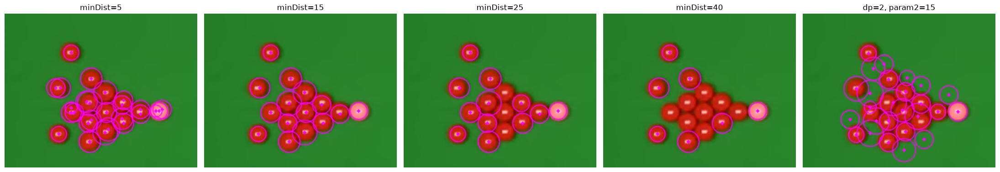

In [14]:
imgs, titles = [], []
for md_ in [5, 15, 25, 40]:
    report(f'minDist={md_}', min_dist=md_)
    imgs.append(draw_circles(mcgill2_c, hough_circles(smooth_m2, min_dist=md_), thickness=1)[ROI_PACK])
    titles.append(f'minDist={md_}')
report('dp=2', dp=2)
report('dp=2, param2=40', dp=2, param2=40)
imgs.append(draw_circles(mcgill2_c, hough_circles(smooth_m2, dp=2), thickness=1)[ROI_PACK])
titles.append('dp=2, param2=15')
show_grid(imgs, titles, ncols=5, figsize=(22, 4.5))

* **`minDist=5`** - po kilka okręgów na jedną bilę, bo komórki akumulatora tuż obok środka bili też przekraczają próg.
* **`minDist=25`** i więcej - stykające się bile w trójkącie mają środki ok. 25 px od siebie, więc część z nich jest tłumiona (3 bile mniej przy 25, 9 przy 40).
* **`minDist=15`** - środek zakresu 8-22, w którym wynik jest ten sam: mniej niż średnica bili, ale więcej niż promień, więc duplikaty jednej bili są tłumione.
* **`dp`** - zostawiam 1 (akumulator w pełnej rozdzielczości). Przy `dp=2` komórka akumulatora jest 2× większa w każdym kierunku i zbiera głosy z większego obszaru, więc ten sam `param2=15` działa dużo łagodniej i pojawia się ok. 50 fałszywych okręgów. Po podniesieniu `param2` do 40 fałszywych już nie ma, ale ginie zielona bila.

### 4.5. Przetwarzanie końcowe okręgów

Przy dobranych parametrach jedyne fałszywe okręgi to **łuzy** (siatki i otwory mają okrągłe kształty o podobnym promieniu): 14 w `mcgill` i 17 w `mcgill2`, po 2-4 na łuzę.
Wszystkie leżą poza polem gry, więc zostawiam okręgi, których środek leży co najmniej 6 px w głąb pola gry od każdej bandy (wykrytej w sekcji 3).
Okręgi łuz leżą najbliżej 2,3 px na zewnątrz bandy, a najbliższa bila (czerwona przy lewej bandzie w `mcgill`) 17,9 px w głąb. Bila dotykająca bandy ma środek ok. 1 promień (12-13 px) od niej, więc margines 6 px (pół promienia) ma zapas z obu stron.

mcgill: 30 okręgów z TH -> 16 na polu gry; najbliższy odrzucony -2.3 px, najbliższy zachowany +17.9 px od bandy
mcgill2: 39 okręgów z TH -> 22 na polu gry; najbliższy odrzucony -4.2 px, najbliższy zachowany +84.8 px od bandy


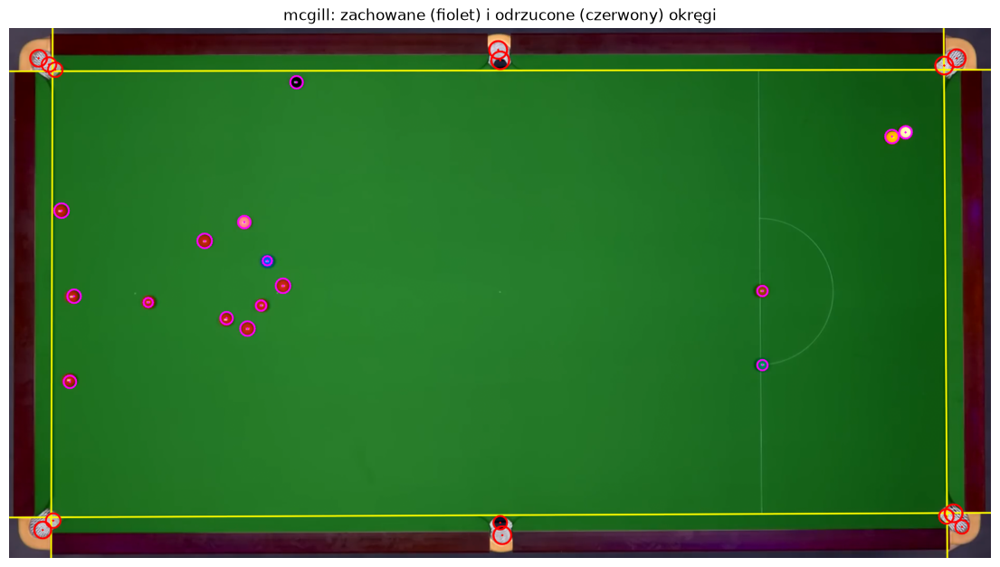

In [15]:
CIRCLE_PARAMS = dict(dp=1, min_dist=15, param1=CANNY_HI, param2=15, min_r=7, max_r=18)

for name, (img, smooth, cushions) in CALIB.items():
    C_raw = hough_circles(smooth, **CIRCLE_PARAMS)
    d = np.array([cushion_dists(x, y, cushions, img.shape).min() for x, y, _ in C_raw])
    print(f'{name}: {len(C_raw)} okręgów z TH -> {(d >= CUSHION_MARGIN).sum()} na polu gry; '
          f'najbliższy odrzucony {d[d < CUSHION_MARGIN].max():+.1f} px, najbliższy zachowany {d[d >= CUSHION_MARGIN].min():+.1f} px od bandy')

C_raw = hough_circles(smooth_m, **CIRCLE_PARAMS)
C_ok = filter_circles(C_raw, cushions_m, mcgill_c.shape)
removed = np.array([c for c in C_raw if not any(np.allclose(c, k) for k in C_ok)]).reshape(-1, 3)
vis = draw_lines(mcgill_c, [(*l, 0) for l in cushions_m.values()])
vis = draw_circles(vis, C_ok)
vis = draw_circles(vis, removed, (0, 0, 255))
show(vis, 'mcgill: zachowane (fiolet) i odrzucone (czerwony) okręgi', figsize=(14, 8));

## 5. Pełny potok

Funkcja `detect` przyjmuje obraz BGR i zwraca:
* `circles` - tablica (N, 3): x, y, r bil (w pikselach),
* `cushions` - słownik strona -> $(\rho, \theta)$ prostej bandy,
* `corners` - 4 narożniki pola gry (przecięcia band),
* oraz obrazy pośrednie do wizualizacji.

Współrzędne są w układzie przyciętego obrazu (względem oryginału przesunięte o 20 px w x i 40 px w y).
Ponieważ celem aplikacji jest położenie bil **w układzie stołu**, przeliczam środki bil przez homografię wyznaczoną z narożników na współrzędne znormalizowane: (0, 0) to lewy górny, a (1, 1) prawy dolny róg pola gry.

In [16]:
def detect(img_bgr):
    img = crop_table(img_bgr)
    smooth, edges = preprocess(img)
    lines = hough_lines(edges, LINE_RHO, LINE_THETA, LINE_THR)
    cushions = select_cushions(img, lines)
    if len(cushions) < 4:
        raise RuntimeError(f'Wykryto tylko bandy: {list(cushions)}')
    corners = table_corners(cushions)
    circles_raw = hough_circles(smooth, **CIRCLE_PARAMS)
    circles = filter_circles(circles_raw, cushions, img.shape)
    # homografia: obraz -> znormalizowany układ pola gry
    Hm = cv2.getPerspectiveTransform(corners, np.float32([[0, 0], [1, 0], [1, 1], [0, 1]]))
    table_xy = cv2.perspectiveTransform(circles[None, :, :2].astype(np.float32), Hm)[0] if len(circles) else np.zeros((0, 2))
    return dict(img=img, circles=circles, cushions=cushions, corners=corners, table_xy=table_xy,
                edges=edges, circles_raw=circles_raw, lines_raw=lines)

def draw_results(res):
    out = draw_lines(res['img'], [(*l, 0) for l in res['cushions'].values()], (0, 255, 255), 2)
    for x, y in res['corners']:
        cv2.drawMarker(out, (int(x), int(y)), (255, 255, 0), cv2.MARKER_CROSS, 40, 3)
    return draw_circles(out, res['circles'], (255, 0, 255), 2)

def demo(name, img):
    res = detect(img)
    print(f"{name}: wykryto {len(res['circles'])} bil (TH dała {len(res['circles_raw'])} okręgów), "
          f"bandy: {len(res['cushions'])} ({len(res['lines_raw'])} prostych z TH)")
    _, axes = plt.subplots(3, 1, figsize=(14, 23))
    show(res['img'], f'{name} - wejście (po przycięciu)', ax=axes[0])
    show(res['edges'], f'{name} - krawędzie', ax=axes[1])
    show(draw_results(res), f'{name} - wykryte bandy, narożniki pola gry i bile', ax=axes[2])
    plt.tight_layout(); plt.show()
    return res

Wynik na obrazach kalibracyjnych:

mcgill: wykryto 16 bil (prawda: 16), bandy: 4
mcgill2: wykryto 22 bil (prawda: 22), bandy: 4


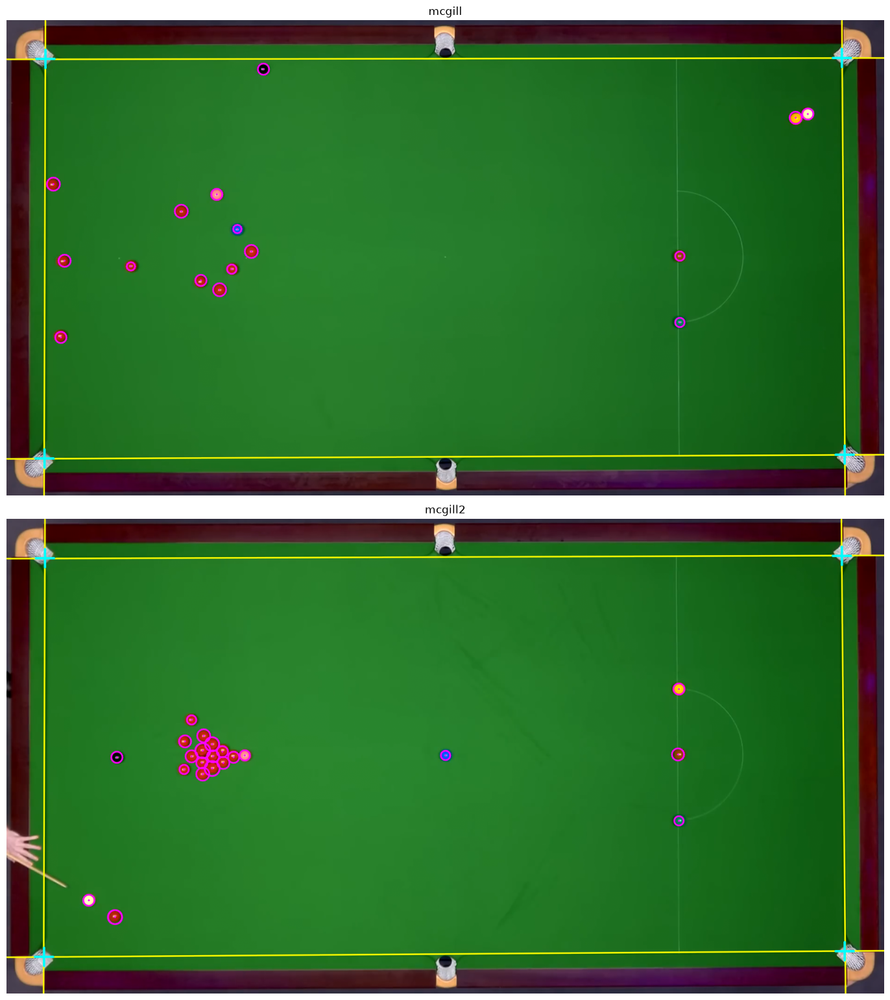

In [17]:
res_mcgill, res_mcgill2 = detect(mcgill), detect(mcgill2)
for name, res in [('mcgill', res_mcgill), ('mcgill2', res_mcgill2)]:
    print(f"{name}: wykryto {len(res['circles'])} bil (prawda: {len(GT_BALLS[name])}), bandy: {len(res['cushions'])}")
show_grid([draw_results(res_mcgill), draw_results(res_mcgill2)], ['mcgill', 'mcgill2'], ncols=1, figsize=(14, 15.5))

## 6. Demonstracja na pozostałych obrazach

trump: wykryto 12 bil (TH dała 27 okręgów), bandy: 4 (62 prostych z TH)


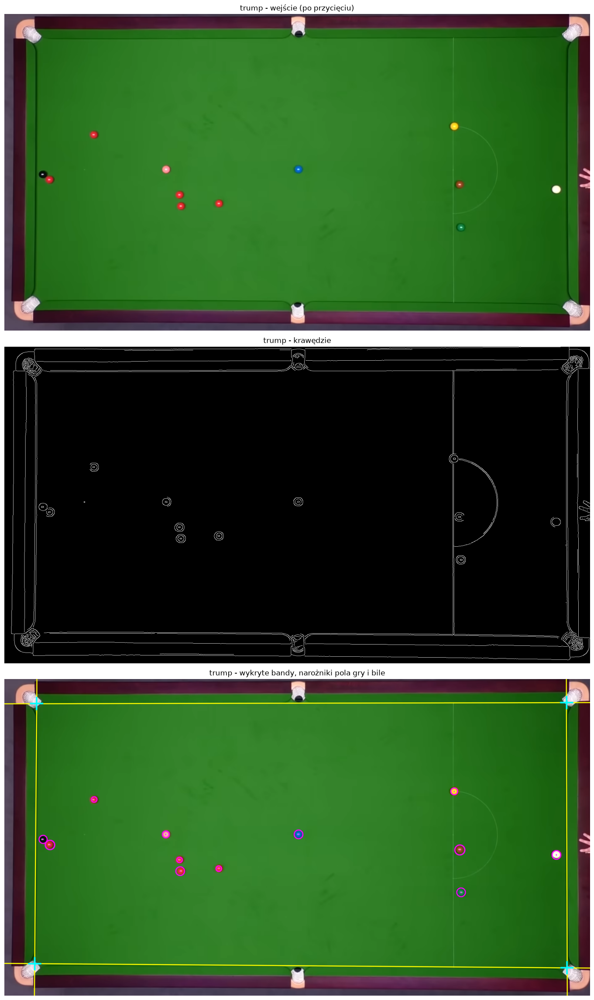

In [18]:
res_trump = demo('trump', trump)

zhao: wykryto 22 bil (TH dała 39 okręgów), bandy: 4 (39 prostych z TH)


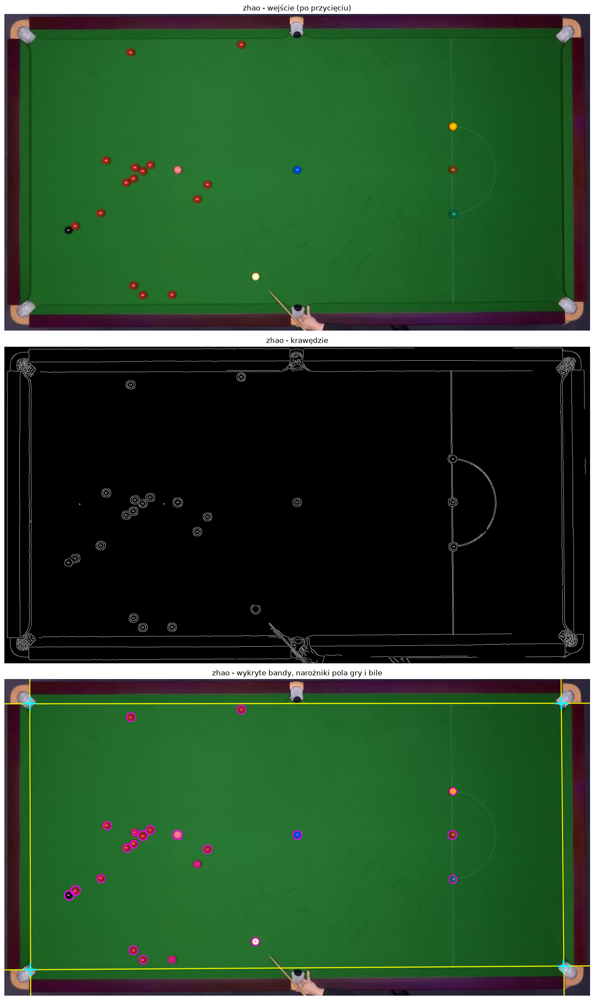

In [19]:
res_zhao = demo('zhao', zhao)

In [20]:
# przykładowy wynik w układzie stołu (dla zespołu zajmującego się geometrią)
print('zhao: położenia bil w układzie pola gry (0..1 wzdłuż, 0..1 w poprzek)')
for (x, y, r), (u, v) in sorted(zip(res_zhao['circles'], res_zhao['table_xy']), key=lambda p: p[1][0]):
    print(f'  piksel ({x:6.1f}, {y:6.1f}), r={r:4.1f}  ->  stół ({u:.3f}, {v:.3f})')

zhao: położenia bil w układzie pola gry (0..1 wzdłuż, 0..1 w poprzek)
  piksel ( 207.5,  694.5), r=14.6  ->  stół (0.072, 0.723)
  piksel ( 228.5,  678.5), r=14.9  ->  stół (0.084, 0.704)
  piksel ( 310.5,  639.5), r=12.7  ->  stół (0.132, 0.659)
  piksel ( 329.5,  469.5), r=12.7  ->  stół (0.143, 0.459)
  piksel ( 393.5,  541.5), r=12.7  ->  stół (0.180, 0.544)
  piksel ( 405.5,  121.5), r=14.1  ->  stół (0.188, 0.050)
  piksel ( 414.5,  870.5), r=13.8  ->  stół (0.191, 0.930)
  piksel ( 415.5,  529.5), r=11.8  ->  stół (0.193, 0.530)
  piksel ( 419.5,  492.5), r=10.3  ->  stół (0.195, 0.487)
  piksel ( 444.5,  501.5), r=15.0  ->  stół (0.210, 0.498)
  piksel ( 446.5,  900.5), r=12.7  ->  stół (0.210, 0.965)
  piksel ( 468.5,  483.5), r=13.8  ->  stół (0.224, 0.476)
  piksel ( 538.5,  899.5), r= 9.6  ->  stół (0.263, 0.965)
  piksel ( 556.5,  499.5), r=15.4  ->  stół (0.275, 0.496)
  piksel ( 618.5,  593.5), r= 9.1  ->  stół (0.311, 0.606)
  piksel ( 652.5,  545.5), r=13.8  ->  stół (

## 7. Podsumowanie

**Obszar stołu**: stały prostokąt `TABLE` (stół z ramą), ten sam dla wszystkich kadrów.

**Przetwarzanie wstępne**: kanał L\* + Gauss 5×5 + Canny 20/40. Kanał L\* daje pełne brzegi czerwonych bil, a niskie progi zachowują słabą ciemną linię bandy.

**Bandy (`HoughLines`)**: `rho=1`, `theta=0.25°`, `threshold=300`.
Surowa TH daje kilkadziesiąt prostych, bo przy każdej bandzie są trzy równoległe krawędzie (brzeg ramy, granica drewno/sukno, banda), każda trafia w kilka sąsiednich komórek akumulatora, a do tego dochodzi linia baulk.
Rozdzielczość kąta 1° była za mała, bo przez perspektywę prawa i dolna banda są nachylone o ułamek stopnia i ich głosy się rozpraszały.
Przetwarzanie końcowe: orientacja → pas przy brzegu obrazu → sukno po obu stronach prostej → średnia krawędzi ciemnej linii. Na wszystkich 4 obrazach daje dokładnie 4 bandy i 4 narożniki pola gry.

**Bile (`HoughCircles`)**: `dp=1`, `minDist=15`, `param1=40`, `param2=15`, promień 7-18 px.
Najważniejszy jest zakres promieni (bez niego kilka tysięcy okręgów), potem `param2` (kompromis: trójkąt a fałszywe okręgi) i `minDist` (mniejszy niż średnica bili, inaczej giną stykające się bile).
Przetwarzanie końcowe usuwa okręgi poza polem gry: wszystkie fałszywe okręgi to łuzy (14-17 na obraz, po 2-4 na łuzę).

**Wyniki**: na wszystkich czterech obrazach wykryte bile zgadzają się z bilami na stole (mcgill 16, mcgill2 22, trump 12, zhao 22), bez fałszywych detekcji.

**Ograniczenia i możliwe źródła błędów**:
* najmniejszy zapas mają bile w środku trójkąta: środkowa ginie już przy `param2=20`, a bile leżące osobno są wykrywane co najmniej do 27,
* zielona bila ma najmniejszy kontrast z suknem i jako jedyna poza trójkątem znika przy `param1=100` i przy `dp=2`,
* promień okręgu nie mierzy dobrze wielkości bili (9-16 px przy rzeczywistym ok. 13 px), bo część okręgów trafia w wewnętrzny pierścień krawędzi, a w trójkącie w krawędzie sąsiadów,
* bila w szczęce łuzy ma środek przy bandzie albo za nią i odpadnie razem z okręgami łuzy,
* prostokąt `TABLE`, zakres promieni, margines i pas przy brzegu zakładają ten sam kadr co w transmisji. Przy innym ujęciu trzeba je przestawić,
* dłoń i kij leżące na bandzie (`mcgill2`, `zhao`) zmniejszają ułamek sukna tylko na krótkim odcinku, więc nie zmieniają wyboru bandy.